# Ch 5: The World Cup stress test

**Question:** hosts bet on the 2026 World Cup. Who placed the bet, did guests and bookings follow, and did the bet pay?

**Facts.** Hard Rock Stadium (Miami Gardens, in Miami-Dade County just south of the Broward line) hosted 7 matches: Jun 15, 21, 24, 27 (group stage), Jul 3 (Round of 32), Jul 11 (quarterfinal), Jul 18 (third-place match). The tournament ran Jun 11 to Jul 19, 2026. The final draw on Dec 5, 2025 set the group-stage matchups; knockout matchups were known only days before each game.

| Section | Question | Main evidence |
|---|---|---|
| 5.1 | Who chased the hype? | Listing titles; logistic regression, decision tree, model comparison |
| 5.2 | Did guests show up? | Reviews vs the year before; reviews that mention the World Cup |
| 5.3 | Were nights booked, and at what price? | Calendars from three scrapes (difference-in-differences); prices |
| 5.4 | Did the bet pay for the hosts who rebranded? | Rebranded vs comparable listings, before and during the tournament |
| 5.5 | Takeaway for our client | |

Data: `data/processed/` (see `docs/data_dictionary.md`). A listing "rebranded" when its title marketed the World Cup (`world_cup_title`). Host type is `host_tier` (all the account's listings in every market), with `broward_tier` (Broward only) as a check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pathlib import Path

DATA = Path("../data/processed")
FIG = Path("figures/ch5")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)
RANDOM_STATE = 6211
DEC, MAR, JUN, SEP = (pd.Timestamp(d) for d in ["2025-12-28", "2026-03-30", "2026-06-29", "2026-09-22"])
BANDS = ["0-10 mi", "10-15 mi", "15-20 mi", "20+ mi"]
BAND_COLORS = {"0-10 mi": "#D62728", "10-15 mi": "#FF7F0E", "15-20 mi": "#7F7F7F", "20+ mi": "#1F77B4"}
TOURNAMENT = ("2026-06-11", "2026-07-19")
FAN = r"world\s*cup|fifa|mundial|soccer|f[uú]tbol"

listings = pd.read_parquet(DATA / "listings_panel.parquet")

def clustered(formula, data, groups, kind="ols"):
    # Regression with standard errors clustered by host: one host's listings (and nights) are not
    # independent observations. Uses only the rows the formula keeps.
    model = (smf.logit if kind == "logit" else smf.ols)(formula, data=data)
    g = data.loc[model.data.row_labels, groups]
    kw = {"disp": 0} if kind == "logit" else {}
    return model.fit(cov_type="cluster", cov_kwds={"groups": g}, **kw)

def effect(m, term, scale=1.0):
    lo, hi = m.conf_int().loc[term]
    return {"estimate": m.params[term] * scale, "ci low": lo * scale, "ci high": hi * scale, "p value": m.pvalues[term]}

## 5.1 Who chased the hype?

**Sample:** the June 29, 2026 scrape (taken during the tournament): short-term listings (minimum stay under 30 nights) open for booking with a believable price (`price_outlier == 0`). One row per listing.

**Features** (all describe the listing or host, not the tournament):

| Feature | Meaning |
|---|---|
| `single_host`, `small_host` | Host type vs pro operators (10+ listings), from `host_tier` |
| `superhost` | Airbnb Superhost status (awarded from past stays and ratings) |
| `mi_to_stadium`, `mi_to_beach` | Distance in miles |
| `entire_home` | Whole home vs a room |
| `bedrooms` | Size (capped at 6) |
| `first_year_listing` | First review within the past year |
| `log_reviews` | Experience: log of (reviews before June 1, 2026 + 1) |

**Price is left out on purpose.** June prices were set during the World Cup, so price would partly be a result of rebranding, not a cause. Prices are studied in 5.3.

In [2]:
reviews_dates = pd.read_parquet(DATA / "reviews.parquet", columns=["listing_id", "date"])
pre_june_reviews = reviews_dates[reviews_dates.date < "2026-06-01"].groupby("listing_id").size()

june = listings[(listings.snapshot_date == JUN) & (listings.mid_term == 0)
                & (listings.bookable == 1) & (listings.price_outlier == 0)].copy()
june["rebranded"] = june["world_cup_title"]
june["single_host"] = (june["host_tier"] == "single").astype(int)
june["small_host"] = (june["host_tier"] == "small (2-9)").astype(int)
june["superhost"] = june["host_is_superhost"].fillna(0).astype(int)
june["mi_to_beach"] = june["mi_to_beach_approx"]
june["entire_home"] = (june["room_type"] == "Entire home/apt").astype(int)
june["bedrooms"] = june["bedrooms"].clip(upper=6)
june["log_reviews"] = np.log1p(june["id"].map(pre_june_reviews).fillna(0))

FEATURES = ["single_host", "small_host", "superhost", "mi_to_stadium", "mi_to_beach",
            "entire_home", "bedrooms", "first_year_listing", "log_reviews"]
june = june.dropna(subset=FEATURES).reset_index(drop=True)
print(f"{len(june):,} listings, {june.rebranded.sum()} rebranded ({june.rebranded.mean():.1%})")

15,809 listings, 464 rebranded (2.9%)


### Who rebranded: the raw rates

In [3]:
def rate_table(col, order=None):
    t = june.groupby(col, observed=True)["rebranded"].agg(listings="size", rebranded="sum", rate="mean")
    return t.reindex(order) if order else t

TIERS = ["single", "small (2-9)", "pro (10+)"]
rates = {
    "Distance to stadium": rate_table("stadium_band", BANDS),
    "Room type": rate_table("room_type"),
    "Host type (host_tier, all markets)": rate_table("host_tier", TIERS),
    "Host type (broward_tier, Broward only)": rate_table("broward_tier", TIERS),
    "Superhost": rate_table("superhost"),
    "Listing age": rate_table("listing_age_group", ["no reviews yet", "first year", "established (1+ year)"]),
}
for name, t in rates.items():
    print(f"\n{name}")
    print(t.to_string(formatters={"rate": "{:.1%}".format}))


Distance to stadium
              listings  rebranded rate
stadium_band                          
0-10 mi           6625        237 3.6%
10-15 mi          3909        126 3.2%
15-20 mi          3011         65 2.2%
20+ mi            2264         36 1.6%

Room type
                 listings  rebranded rate
room_type                                
Entire home/apt     13213        446 3.4%
Hotel room            218          0 0.0%
Private room         2272         18 0.8%
Shared room           106          0 0.0%

Host type (host_tier, all markets)
             listings  rebranded rate
host_tier                            
single           3055         86 2.8%
small (2-9)      4980        167 3.4%
pro (10+)        7774        211 2.7%

Host type (broward_tier, Broward only)
              listings  rebranded rate
broward_tier                          
single            3875        132 3.4%
small (2-9)       5418        155 2.9%
pro (10+)         6516        177 2.7%

Superhost
          

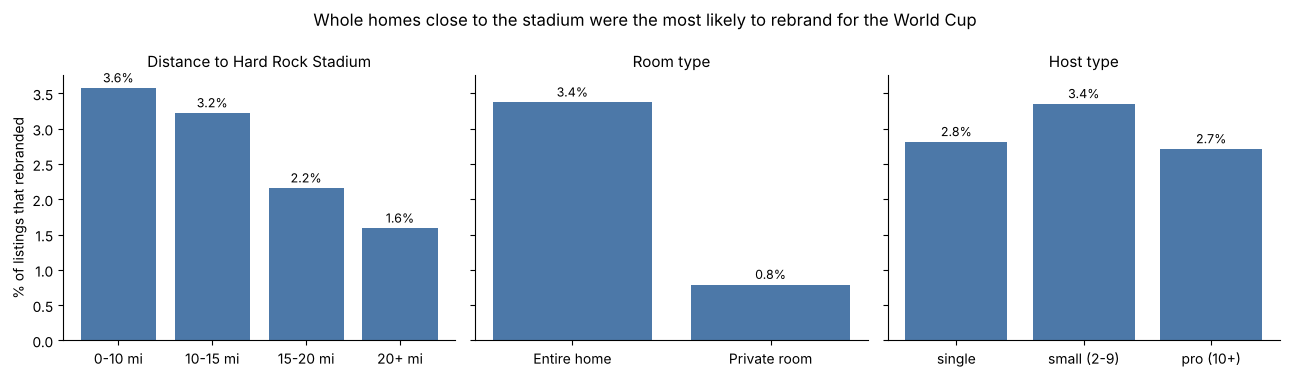

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
room = rates["Room type"].loc[["Entire home/apt", "Private room"]]
panels = [(rates["Distance to stadium"], "Distance to Hard Rock Stadium", BANDS),
          (room, "Room type", ["Entire home", "Private room"]),
          (rates["Host type (host_tier, all markets)"], "Host type", TIERS)]
for ax, (t, title, labels) in zip(axes, panels):
    ax.bar(labels, t["rate"] * 100, color="#4C78A8")
    for i, v in enumerate(t["rate"] * 100):
        ax.text(i, v + 0.08, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(title, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("% of listings that rebranded")
fig.suptitle("Whole homes close to the stadium were the most likely to rebrand for the World Cup", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "5_1_rebrand_rates.png", dpi=150)
plt.show()

### Rebranding was a host decision

If a host decides for several listings at once, those listings are not independent. Every model below accounts for this (standard errors grouped by host, train/test splits by host).

In [5]:
by_host = june.groupby("host_id")["rebranded"].agg(listings="size", rebranded="sum")
reb_hosts = by_host[by_host.rebranded > 0]
multi = reb_hosts[reb_hosts.listings >= 2]
print(f"{june.rebranded.sum()} rebranded listings came from {len(reb_hosts)} hosts")
print(f"Largest single host: {reb_hosts.rebranded.max()} rebranded listings")
print(f"Share of rebranded listings from hosts with 5+ rebrands: "
      f"{reb_hosts.loc[reb_hosts.rebranded >= 5, 'rebranded'].sum() / june.rebranded.sum():.0%}")
print(f"Rebranding hosts with only 1 listing in this sample: {(reb_hosts.listings == 1).sum()}")
print(f"Rebranding hosts with 2+ listings: {len(multi)}; of those, rebranded all of them: "
      f"{(multi.rebranded == multi.listings).sum()}")

464 rebranded listings came from 232 hosts
Largest single host: 38 rebranded listings
Share of rebranded listings from hosts with 5+ rebrands: 38%
Rebranding hosts with only 1 listing in this sample: 134
Rebranding hosts with 2+ listings: 98; of those, rebranded all of them: 26


### Logistic regression: which factors matter when compared together?

The raw rates mix effects together (for example, whole homes may also sit closer to the stadium). Logistic regression estimates each factor while holding the others constant. We read **odds ratios**: 1.5 means 50% higher odds of rebranding, 0.8 means 20% lower. Standard errors are clustered by host. The model is unweighted because the goal is explanation; imbalance does not change which way each factor points.

**Pseudo R-squared** (McFadden) measures how much better the model predicts than a model with no features: 0 means no better, and values around 0.2 or more are considered a good fit for this kind of model.

In [6]:
X = sm.add_constant(june[FEATURES].astype(float))
logit = sm.Logit(june["rebranded"], X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": june["host_id"]})
odds = pd.DataFrame({"odds ratio": np.exp(logit.params), "ci low": np.exp(logit.conf_int()[0]),
                     "ci high": np.exp(logit.conf_int()[1]), "p value": logit.pvalues}).drop("const")
odds["significant (p < 0.05)"] = np.where(odds["p value"] < 0.05, "yes", "")
print(f"Pseudo R-squared: {logit.prsquared:.3f}")
print(f"Odds at 10 miles vs at the stadium: {np.exp(logit.params['mi_to_stadium'] * 10):.2f}")
odds.sort_values("odds ratio")

Pseudo R-squared: 0.049
Odds at 10 miles vs at the stadium: 0.53


,odds ratio,ci low,ci high,p value,significant (p < 0.05)
mi_to_stadium,0.939,0.903,0.977,0.002,yes
log_reviews,0.958,0.874,1.049,0.354,
single_host,0.968,0.546,1.717,0.911,
mi_to_beach,1.034,0.985,1.086,0.176,
small_host,1.222,0.669,2.233,0.514,
bedrooms,1.227,1.125,1.338,0.000,yes
first_year_listing,1.370,0.948,1.979,0.094,
superhost,1.518,0.873,2.639,0.139,
entire_home,4.100,2.299,7.311,0.000,yes


**Multicollinearity check (VIF).** If two features carry the same information, their odds ratios become unstable. A variance inflation factor above about 5 would be a warning sign.

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                index=FEATURES, name="VIF").sort_values(ascending=False)
vif.round(2)

log_reviews          1.250
single_host          1.230
entire_home          1.200
small_host           1.200
superhost            1.180
mi_to_beach          1.170
bedrooms             1.100
first_year_listing   1.070
mi_to_stadium        1.070
Name: VIF, dtype: float64

### Can listing traits predict who rebranded?

Only about 3% of listings rebranded, so a model that always says "no" is 97% accurate and useless. The setup:
1. **Train/test split by host** (about two thirds / one third), stratified so both keep the 3% share. No host has listings on both sides.
2. **Five ways to handle the imbalance:** no adjustment, class weights (mistakes on rebranded listings cost more), random undersampling (drop "not rebranded" listings until the classes are equal), random oversampling (repeat rebranded listings), SMOTE (create synthetic rebranded listings between similar real ones; not covered in class yet). Resampling happens only inside the training part of each fold (an `imblearn` pipeline), so nothing copied or synthetic is ever scored.
3. **Five course models,** each tuned with 5-fold cross-validation split by host: logistic regression, decision tree, random forest, SVM (no resampling: it would multiply training time, and class weights do the same job) and a neural network (scikit-learn's has no class weights, so resampling only).
4. **Metrics for a rare class:** PR AUC (average precision; random guessing scores the rebrand rate, about 0.03) and ROC AUC (0.5 = random). We report the cross-validated mean and its spread across the 5 folds.

The full comparison is an appendix table; the charts use one model.

In [8]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             precision_recall_curve)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE
import joblib

outer = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(outer.split(june[FEATURES], june["rebranded"], groups=june["host_id"]))
X_train, X_test = june[FEATURES].iloc[train_idx], june[FEATURES].iloc[test_idx]
y_train, y_test = june["rebranded"].iloc[train_idx], june["rebranded"].iloc[test_idx]
groups_train = june["host_id"].iloc[train_idx]
print(f"train: {len(y_train):,} ({y_train.mean():.1%} rebranded) | test: {len(y_test):,} ({y_test.mean():.1%})")
print("hosts on both sides:", len(set(groups_train) & set(june["host_id"].iloc[test_idx])))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
samplers = {"No adjustment": None, "Class weights": None,
            "Undersampling": RandomUnderSampler(random_state=RANDOM_STATE),
            "Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
            "SMOTE": SMOTE(random_state=RANDOM_STATE)}
ALL = list(samplers)
model_specs = {
    "Logistic regression": (lambda w: LogisticRegression(class_weight=w, max_iter=2000),
                            {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}, ALL),
    "Decision tree": (lambda w: DecisionTreeClassifier(class_weight=w, random_state=RANDOM_STATE),
                      {"model__max_depth": [3, 4, 6, 8, 10], "model__min_samples_leaf": [25, 50, 100]}, ALL),
    "Random forest": (lambda w: RandomForestClassifier(n_estimators=200, class_weight=w, n_jobs=-1,
                                                       random_state=RANDOM_STATE),
                      {"model__max_depth": [6, 8, 12], "model__min_samples_leaf": [10, 25, 50]}, ALL),
    "SVM (RBF kernel)": (lambda w: SVC(kernel="rbf", class_weight=w),
                         {"model__C": [0.1, 1, 10]}, ["No adjustment", "Class weights"]),
    "Neural network": (lambda w: MLPClassifier(max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
                       {"model__hidden_layer_sizes": [(16,), (32, 16)], "model__alpha": [0.0001, 0.01]},
                       ["No adjustment", "Undersampling", "Oversampling", "SMOTE"]),
}

def scores(model, X):
    # Probability where the model has one, otherwise the SVM's decision score (ranking is all we need)
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

# Each tuned model is saved as it finishes, so a rerun skips finished ones. Delete cache/ch5 to retune.
CACHE = Path("cache/ch5")
# The cache name includes a fingerprint of the training data, so a data rebuild retunes automatically
import hashlib
DATA_TAG = hashlib.md5(pd.util.hash_pandas_object(june[FEATURES + ["rebranded", "host_id"]], index=False).values.tobytes()).hexdigest()[:8]
CACHE.mkdir(parents=True, exist_ok=True)
rows, fitted = [], {}
for model_name, (make_model, grid, allowed) in model_specs.items():
    for sampler_name in allowed:
        cache_file = CACHE / f"{model_name}_{sampler_name}_{DATA_TAG}.joblib".replace(" ", "_")
        if cache_file.exists():
            search, row = joblib.load(cache_file)
        else:
            weight = "balanced" if sampler_name == "Class weights" else None
            steps = [("scale", StandardScaler())]
            if samplers[sampler_name] is not None:
                steps.append(("sample", samplers[sampler_name]))
            steps.append(("model", make_model(weight)))
            search = GridSearchCV(ImbPipeline(steps), grid, cv=cv, n_jobs=-1, refit="pr_auc",
                                  scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
            search.fit(X_train, y_train, groups=groups_train)
            b = search.best_index_
            p = scores(search, X_test)
            row = {"model": model_name, "imbalance method": sampler_name,
                   "best settings": ", ".join(f"{k.split('__')[1]}={v}" for k, v in search.best_params_.items()),
                   "CV PR AUC": search.cv_results_["mean_test_pr_auc"][b],
                   "CV PR AUC sd": search.cv_results_["std_test_pr_auc"][b],
                   "CV ROC AUC": search.cv_results_["mean_test_roc_auc"][b],
                   "test PR AUC": average_precision_score(y_test, p), "test ROC AUC": roc_auc_score(y_test, p)}
            joblib.dump((search, row), cache_file)
        fitted[(model_name, sampler_name)] = search
        rows.append(row)
comparison = pd.DataFrame(rows).sort_values("CV PR AUC", ascending=False).reset_index(drop=True)
comparison.to_csv(FIG / "5_1_method_comparison.csv", index=False)
best, chosen_row = comparison.iloc[0], comparison[(comparison.model == "Logistic regression") & (comparison["imbalance method"] == "Class weights")].iloc[0]
print(f"Random guessing PR AUC = {y_test.mean():.3f}")
print(f"Top CV row: {best['model']}, {best['imbalance method']}: {best['CV PR AUC']:.3f} +/- {best['CV PR AUC sd']:.3f}")
print(f"Rows within one fold-to-fold sd of the top row: {(comparison['CV PR AUC'] >= best['CV PR AUC'] - best['CV PR AUC sd']).sum()} of {len(comparison)}")
print(f"Logistic regression with class weights: CV {chosen_row['CV PR AUC']:.3f} +/- {chosen_row['CV PR AUC sd']:.3f}, test {chosen_row['test PR AUC']:.3f}")
print("Rank of the top CV row on the test set:", int(comparison["test PR AUC"].rank(ascending=False)[0]), "of", len(comparison))
comparison

train: 10,540 (2.9% rebranded) | test: 5,269 (2.9%)
hosts on both sides: 0


Random guessing PR AUC = 0.029
Top CV row: Random forest, No adjustment: 0.074 +/- 0.037
Rows within one fold-to-fold sd of the top row: 21 of 21
Logistic regression with class weights: CV 0.051 +/- 0.013, test 0.061
Rank of the top CV row on the test set: 10 of 21


,model,imbalance method,best settings,CV PR AUC,CV PR AUC sd,CV ROC AUC,test PR AUC,test ROC AUC
0,Random forest,No adjustment,"max_depth=12, min_samples_leaf=10",0.074,0.037,0.652,0.049,0.642
1,Decision tree,No adjustment,"max_depth=3, min_samples_leaf=50",0.064,0.025,0.626,0.042,0.653
2,Random forest,Oversampling,"max_depth=8, min_samples_leaf=50",0.063,0.025,0.670,0.053,0.663
3,Random forest,Class weights,"max_depth=12, min_samples_leaf=25",0.063,0.029,0.667,0.051,0.652
4,Decision tree,Oversampling,"max_depth=10, min_samples_leaf=100",0.062,0.029,0.632,0.054,0.650
5,Random forest,Undersampling,"max_depth=6, min_samples_leaf=10",0.060,0.020,0.670,0.064,0.683
6,Decision tree,Class weights,"max_depth=8, min_samples_leaf=100",0.056,0.023,0.608,0.049,0.645
7,SVM (RBF kernel),Class weights,C=0.1,0.055,0.019,0.654,0.047,0.654
8,Random forest,SMOTE,"max_depth=12, min_samples_leaf=25",0.055,0.025,0.652,0.047,0.644
9,Neural network,SMOTE,"alpha=0.01, hidden_layer_sizes=(16,)",0.054,0.019,0.636,0.048,0.645


**How to read this table.** The fold-to-fold spread (`CV PR AUC sd`) is about as large as the differences between the rows, so the models are **statistically tied**: no model or imbalance method clearly wins, and all of them score close to random guessing on hosts they never saw. Picking the top row as a "winner" would mostly be picking a lucky fold, and the differences between imbalance methods are too small to read anything into. For the charts below we use the simplest model in the tie, **logistic regression with class weights**: it matches the odds-ratio model above and is easy to explain.

Two notes on the table. "Within one standard deviation" uses the top row's spread, which is the largest in the table; the neural network and the SVM without any imbalance adjustment are close to random on the test set (ROC AUC about 0.54 and 0.56), so the fair reading is 19 rows tied and 2 near random. Several best settings sit at the edge of their grid (for example C = 100 for logistic regression, max_depth = 12 for the random forest); widening the grid would not change the tie, because the scores are flat across settings.

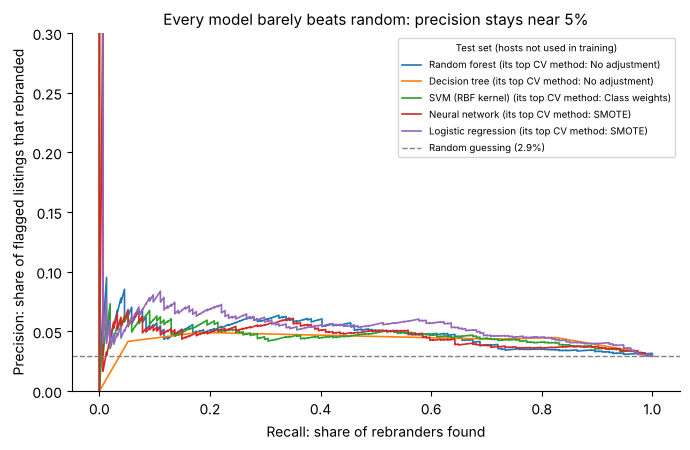

In [9]:
chosen = fitted[("Logistic regression", "Class weights")]
p_chosen = chosen.predict_proba(X_test)[:, 1]

fig, ax = plt.subplots(figsize=(7, 4.6))
for _, r in comparison.drop_duplicates("model").iterrows():
    prec, rec, _ = precision_recall_curve(y_test, scores(fitted[(r["model"], r["imbalance method"])], X_test))
    ax.plot(rec, prec, lw=1.2, label=f"{r['model']} (its top CV method: {r['imbalance method']})")
ax.axhline(y_test.mean(), color="gray", ls="--", lw=1, label=f"Random guessing ({y_test.mean():.1%})")
ax.set_xlabel("Recall: share of rebranders found")
ax.set_ylabel("Precision: share of flagged listings that rebranded")
ax.set_ylim(0, 0.3)
ax.set_title("Every model barely beats random: precision stays near 5%", fontsize=11)
ax.legend(fontsize=7, title="Test set (hosts not used in training)", title_fontsize=7)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_1_precision_recall.png", dpi=150)
plt.show()

### Choosing a cutoff, and lift by decile (logistic regression with class weights)

        listings flagged  rebranders found   of  recall  precision
cutoff                                                            
0.300               3989               146  154   0.948      0.037
0.400               3122               132  154   0.857      0.042
0.500               1929               103  154   0.669      0.053
0.600                893                53  154   0.344      0.059
0.700                314                22  154   0.143      0.070 

Confusion matrix at cutoff 0.5 (rows = actual, columns = predicted)
predicted     0     1
actual               
0          3289  1826
1            51   103 



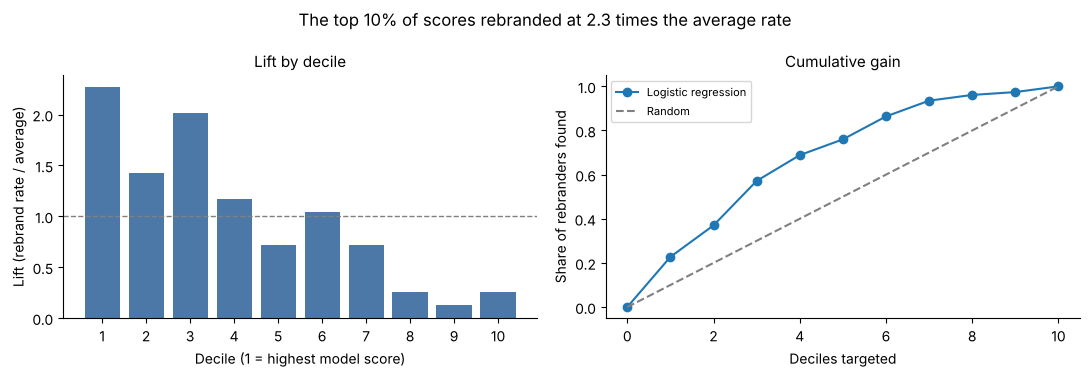

,listings,rebranded,rate,lift,cumulative gain
decile,,,,,
1,527,35,0.066,2.272,0.227
2,527,22,0.042,1.428,0.370
3,527,31,0.059,2.013,0.571
4,527,18,0.034,1.169,0.688
5,527,11,0.021,0.714,0.760
6,526,16,0.030,1.041,0.864
7,527,11,0.021,0.714,0.935
8,527,4,0.008,0.260,0.961
9,527,2,0.004,0.130,0.974


In [10]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (p_chosen >= t).astype(int)
    rows.append({"cutoff": t, "listings flagged": int(pred.sum()),
                 "rebranders found": int((pred & y_test.values).sum()), "of": int(y_test.sum()),
                 "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0)})
print(pd.DataFrame(rows).set_index("cutoff").round(3).to_string(), "\n")
print("Confusion matrix at cutoff 0.5 (rows = actual, columns = predicted)")
print(pd.crosstab(pd.Series(y_test.values, name="actual"), pd.Series((p_chosen >= 0.5).astype(int), name="predicted")), "\n")

deciles = pd.DataFrame({"score": p_chosen, "rebranded": y_test.values})
deciles["decile"] = pd.qcut(deciles["score"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = deciles.groupby("decile", observed=True)["rebranded"].agg(listings="size", rebranded="sum")
lift["rate"] = lift["rebranded"] / lift["listings"]
lift["lift"] = lift["rate"] / deciles["rebranded"].mean()
lift["cumulative gain"] = lift["rebranded"].cumsum() / lift["rebranded"].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(lift.index.astype(str), lift["lift"], color="#4C78A8")
axes[0].axhline(1, color="gray", ls="--", lw=1)
axes[0].set_xlabel("Decile (1 = highest model score)")
axes[0].set_ylabel("Lift (rebrand rate / average)")
axes[0].set_title("Lift by decile", fontsize=11)
axes[1].plot(range(0, 11), [0] + list(lift["cumulative gain"]), marker="o", label="Logistic regression")
axes[1].plot([0, 10], [0, 1], color="gray", ls="--", label="Random")
axes[1].set_xlabel("Deciles targeted")
axes[1].set_ylabel("Share of rebranders found")
axes[1].set_title("Cumulative gain", fontsize=11)
axes[1].legend(fontsize=8)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"The top 10% of scores rebranded at {lift['lift'].iloc[0]:.1f} times the average rate", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "5_1_lift_gain.png", dpi=150)
plt.show()
lift.round(3)

### Which features does the model rely on? (permutation importance)

Shuffle one feature at a time on the test set and measure how much the PR AUC drops. A bigger drop means the model leans on that feature more. Repeated 20 times.

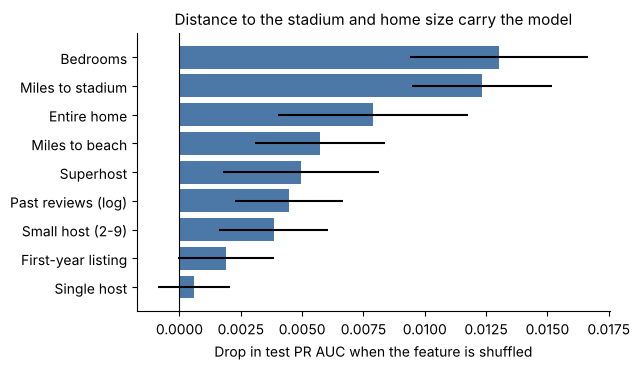

,drop in PR AUC,sd
Bedrooms,0.013,0.004
Miles to stadium,0.012,0.003
Entire home,0.008,0.004
Miles to beach,0.006,0.003
Superhost,0.005,0.003
Past reviews (log),0.004,0.002
Small host (2-9),0.004,0.002
First-year listing,0.002,0.002
Single host,0.001,0.002


In [11]:
imp = permutation_importance(chosen, X_test, y_test, scoring="average_precision", n_repeats=20,
                             random_state=RANDOM_STATE)
PLAIN = {"single_host": "Single host", "small_host": "Small host (2-9)", "superhost": "Superhost",
         "mi_to_stadium": "Miles to stadium", "mi_to_beach": "Miles to beach", "entire_home": "Entire home",
         "bedrooms": "Bedrooms", "first_year_listing": "First-year listing", "log_reviews": "Past reviews (log)"}
importance = pd.DataFrame({"drop in PR AUC": imp.importances_mean, "sd": imp.importances_std},
                          index=[PLAIN[f] for f in FEATURES]).sort_values("drop in PR AUC")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(importance.index, importance["drop in PR AUC"], xerr=importance["sd"], color="#4C78A8")
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Drop in test PR AUC when the feature is shuffled")
ax.set_title("Distance to the stadium and home size carry the model", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_1_importance.png", dpi=150)
plt.show()
importance.sort_values("drop in PR AUC", ascending=False).round(4)

### The decision tree: rules a host would recognize

A shallow tree (depth 3, class weights) turns the same pattern into readable rules. Blue boxes lean "rebranded", orange boxes lean "not". Because of the class weights, "value" shows **weighted** shares, so the top box reads 50/50 even though only 3% rebranded.

Test ROC AUC of this tree: 0.632


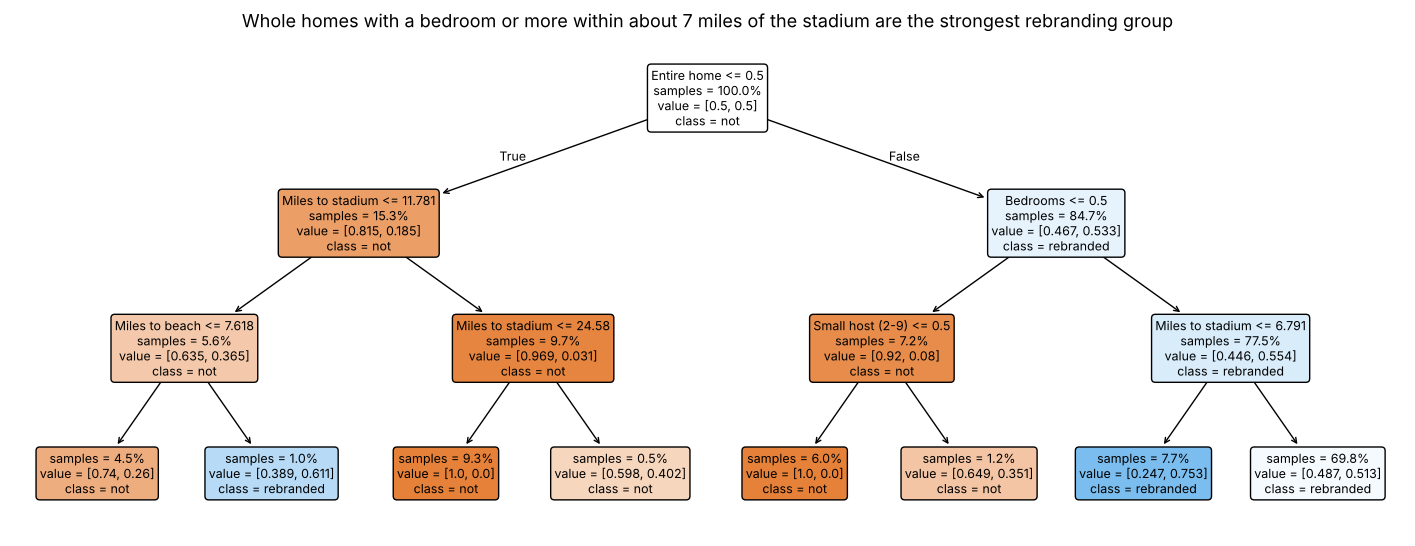

,listings,rebranded,rate,rule
leaf,,,,
13,1174,92,0.078,entire_home > 0.5 and bedrooms > 0.5 and mi_to_stadium <= 6.8
4,167,7,0.042,entire_home <= 0.5 and mi_to_stadium <= 11.8 and mi_to_beach > 7.6
14,10929,352,0.032,entire_home > 0.5 and bedrooms > 0.5 and mi_to_stadium > 6.8
7,77,1,0.013,entire_home <= 0.5 and mi_to_stadium > 11.8 and mi_to_stadium > 24.6
11,195,2,0.010,entire_home > 0.5 and bedrooms <= 0.5 and small_host > 0.5
3,792,5,0.006,entire_home <= 0.5 and mi_to_stadium <= 11.8 and mi_to_beach <= 7.6
6,1560,5,0.003,entire_home <= 0.5 and mi_to_stadium > 11.8 and mi_to_stadium <= 24.6
10,915,0,0.000,entire_home > 0.5 and bedrooms <= 0.5 and small_host <= 0.5


In [12]:
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, class_weight="balanced",
                              random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"Test ROC AUC of this tree: {roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]):.3f}")
fig, ax = plt.subplots(figsize=(18, 6.5))
plot_tree(tree, feature_names=[PLAIN[f] for f in FEATURES], class_names=["not", "rebranded"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=9, ax=ax)
ax.set_title("Whole homes with a bedroom or more within about 7 miles of the stadium are the strongest rebranding group", fontsize=13)
fig.savefig(FIG / "5_1_decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

def leaf_rules(model, names):
    # The chain of splits that leads to each leaf, as readable text
    t, rules = model.tree_, {}
    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = " and ".join(conds)
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        walk(t.children_left[node], conds + [f"{f} <= {thr:.1f}"])
        walk(t.children_right[node], conds + [f"{f} > {thr:.1f}"])
    walk(0, [])
    return rules

# Actual (unweighted) rebrand rate in each leaf, training and test listings
leaves = pd.DataFrame({"leaf": np.concatenate([tree.apply(X_train), tree.apply(X_test)]),
                       "rebranded": np.concatenate([y_train.values, y_test.values])})
leaf_table = leaves.groupby("leaf")["rebranded"].agg(listings="size", rebranded="sum", rate="mean")
leaf_table["rule"] = leaf_table.index.map(leaf_rules(tree, FEATURES))
pd.set_option("display.max_colwidth", 120)
leaf_table.sort_values("rate", ascending=False)

### Check: does undersampling change the answer?

Instead of class weights, train on all rebranded listings plus an equal number of randomly picked others, 25 times with different random picks. If the factors point the same way as in the weighted model, the finding does not depend on how we handled the imbalance.

In [13]:
from sklearn.pipeline import make_pipeline
rng = np.random.default_rng(RANDOM_STATE)
pos, neg = june[june.rebranded == 1], june[june.rebranded == 0]
coefs = []
for i in range(25):
    sample = pd.concat([pos, neg.sample(len(pos), random_state=int(rng.integers(1e9)))])
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(sample[FEATURES], sample["rebranded"])
    coefs.append(m[-1].coef_[0])
under = pd.DataFrame(coefs, columns=FEATURES)
weighted = chosen.best_estimator_[-1].coef_[0]
compare = pd.DataFrame({"weighted model": weighted, "undersampled (mean of 25)": under.mean().values,
                        "undersampled range": [f"{lo:.2f} to {hi:.2f}" for lo, hi in zip(under.min(), under.max())]},
                       index=FEATURES).sort_values("weighted model", key=abs, ascending=False)
compare["same direction"] = np.sign(compare["weighted model"]) == np.sign(compare["undersampled (mean of 25)"])
print("Standardized coefficients (bigger = stronger; sign = direction)")
compare

Standardized coefficients (bigger = stronger; sign = direction)


,weighted model,undersampled (mean of 25),undersampled range,same direction
entire_home,0.540,0.423,0.32 to 0.58,True
mi_to_stadium,-0.377,-0.358,-0.52 to -0.26,True
superhost,0.296,0.182,0.10 to 0.32,True
bedrooms,0.256,0.356,0.25 to 0.50,True
first_year_listing,0.160,0.151,0.08 to 0.25,True
mi_to_beach,0.134,0.116,-0.02 to 0.22,True
log_reviews,-0.123,-0.079,-0.25 to 0.03,True
small_host,0.085,0.110,0.01 to 0.21,True
single_host,0.036,0.003,-0.11 to 0.10,True


### What 5.1 shows


- **Who bet:** 464 of 15,809 June listings (2.9%) marketed the World Cup in their title. They came from 232 hosts: 134 of those hosts had one listing in this sample, and 38% of rebranded listings came from hosts who rebranded 5 or more. Of the 98 rebranding hosts with 2+ listings, only 26 rebranded all of them.
- **What kind of listing:** whole homes close to the stadium. The rate falls from 3.6% within 10 miles to 1.6% beyond 20 miles; entire homes 3.4% vs private rooms 0.8%. Holding the other factors constant (logistic regression, clustered by host), an entire home has 4.1 times the odds (95% CI 2.3 to 7.3), each extra bedroom 1.23 times (1.13 to 1.34), and the odds at 10 miles are about half (0.53) of those at the stadium. The tree's strongest group, entire homes with 1+ bedroom within 6.8 miles, rebranded at 7.8% (92 of 1,174) vs 3.2% for entire homes with 1+ bedroom farther away.
- **Not a pro strategy:** pros and independents rebranded at similar rates (host_tier: single 2.8%, small 3.4%, pro 2.7%; broward_tier: 3.4%, 2.9%, 2.7%), and host type, Superhost status, listing age, beach distance and past reviews are not significant once size and distance are in the model.
- **Hard to predict:** pseudo R-squared is 0.049. Measured against the top row's fold-to-fold spread, 19 of the 21 model and imbalance-method combinations are statistically tied (CV PR AUC 0.045 to 0.074 vs 0.029 for random guessing), and the neural network and SVM without any imbalance adjustment are near random; the top CV row ranks 10th of 21 on the test set. With the class-weighted logistic regression (CV 0.051 +/- 0.013, test 0.061), the top 10% of scores rebranded at 2.3 times the average rate, and at a 0.5 cutoff it finds 67% of rebranders but only 5.3% of flagged listings rebranded. Bedrooms and distance to the stadium carry the model (permutation importance), and undersampling 25 times gives the same direction for every factor.
- **Meaning:** rebranding was a size and location bet that every kind of host made. Beyond size and location, who rebranded looks close to random.

## 5.2 Did guests show up?

Reviews are a demand signal. Guests review about 2 weeks after checkout, so stays during the tournament (Jun 11 to Jul 19) show up in reviews dated about **Jun 13 to Aug 2**. We compare that window with the same dates in 2025, and use January to May as the "normal" comparison.

**Same listings only:** listings with a first review before 2025 that were still listed in both the June and September 2026 scrapes. Listings that left Airbnb lose their later reviews from the data, so including them would look like lost demand.

Reviews are an indirect signal (only some guests write one), so 5.3 checks bookings with the calendar.

**The 2025 comparison was not soccer-free.** Hard Rock Stadium also hosted 8 FIFA Club World Cup matches from Jun 14 to Jul 1, 2025 (a smaller event). If that lifted 2025 reviews near the stadium, comparing with 2025 understates a 2026 World Cup lift. The calendar comparisons in 5.3 stay within 2026 and are not affected.

In [14]:
rv = pd.read_parquet(DATA / "reviews.parquet", columns=["listing_id", "date", "comments", "language", "stadium_band"])
first_review = listings.groupby("id")["first_review"].min()
in_jun = set(listings.loc[listings.snapshot_date == JUN, "id"])
in_sep = set(listings.loc[listings.snapshot_date == SEP, "id"])
established = [i for i in first_review[first_review < "2025-01-01"].index if i in in_jun and i in in_sep]
same = rv[rv.listing_id.isin(established)]
print(f"Same listings: {len(established):,}")

def window_count(year, start, end):
    w = same[(same.date >= f"{year}-{start}") & (same.date <= f"{year}-{end}")]
    return w.groupby("stadium_band", observed=False).size().reindex(BANDS)

counts = pd.DataFrame({"Jan to May 2025": window_count(2025, "01-01", "05-31"), "Jan to May 2026": window_count(2026, "01-01", "05-31"),
                       "Jun 13 to Aug 2 2025": window_count(2025, "06-13", "08-02"), "Jun 13 to Aug 2 2026": window_count(2026, "06-13", "08-02")})
ratios = pd.DataFrame({"Jan to May": counts["Jan to May 2026"] / counts["Jan to May 2025"],
                       "Tournament reviews (Jun 13 to Aug 2)": counts["Jun 13 to Aug 2 2026"] / counts["Jun 13 to Aug 2 2025"]})
ratios["change vs Jan to May (points)"] = (ratios.iloc[:, 1] - ratios.iloc[:, 0]) * 100
print(counts.to_string(), "\n")
print("Reviews in 2026 / same dates in 2025, same listings")
ratios.round(3)

Same listings: 8,480
              Jan to May 2025  Jan to May 2026  Jun 13 to Aug 2 2025  Jun 13 to Aug 2 2026
stadium_band                                                                              
0-10 mi                 20341            20621                  5582                  5777
10-15 mi                19798            19056                  5340                  5104
15-20 mi                12175            12486                  3699                  3798
20+ mi                   7867             7581                  2338                  2503 

Reviews in 2026 / same dates in 2025, same listings


,Jan to May,Tournament reviews (Jun 13 to Aug 2),change vs Jan to May (points)
stadium_band,,,
0-10 mi,1.014,1.035,2.117
10-15 mi,0.963,0.956,-0.672
15-20 mi,1.026,1.027,0.122
20+ mi,0.964,1.071,10.693


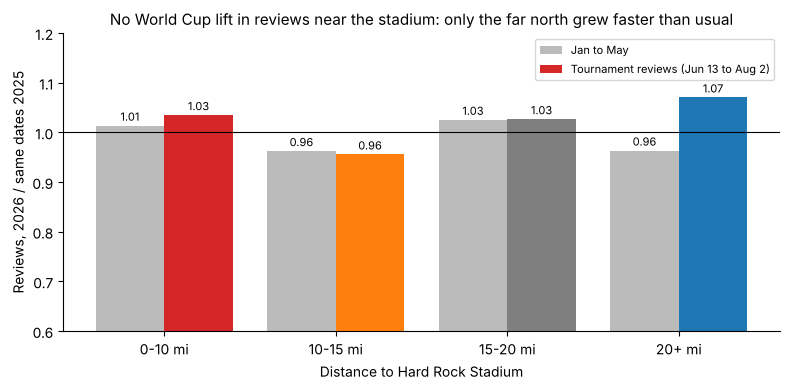

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(BANDS))
ax.bar(x - 0.2, ratios["Jan to May"], width=0.4, color="#BBBBBB", label="Jan to May")
ax.bar(x + 0.2, ratios["Tournament reviews (Jun 13 to Aug 2)"], width=0.4,
       color=[BAND_COLORS[b] for b in BANDS], label="Tournament reviews (Jun 13 to Aug 2)")
for i, (a, b) in enumerate(zip(ratios.iloc[:, 0], ratios.iloc[:, 1])):
    ax.text(i - 0.2, a + 0.01, f"{a:.2f}", ha="center", fontsize=8)
    ax.text(i + 0.2, b + 0.01, f"{b:.2f}", ha="center", fontsize=8)
ax.axhline(1, color="black", lw=0.8)
ax.set_xticks(x, BANDS)
ax.set_xlabel("Distance to Hard Rock Stadium")
ax.set_ylabel("Reviews, 2026 / same dates 2025")
ax.set_ylim(0.6, max(1.2, ratios.iloc[:, :2].max().max() + 0.08))
ax.set_title("No World Cup lift in reviews near the stadium: only the far north grew faster than usual", fontsize=11)
ax.legend(fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_2_reviews_vs_last_year.png", dpi=150)
plt.show()

**Check on the 2025 baseline.** Hard Rock hosted the Club World Cup in June 2025. If that lifted 2025 reviews near the stadium, the comparison above would understate 2026. Same test one year earlier: summer 2025 vs summer 2024, against January to May, on listings with a first review before 2024.

In [16]:
established_24 = [i for i in first_review[first_review < "2024-01-01"].index if i in in_jun and i in in_sep]
same_24 = rv[rv.listing_id.isin(established_24)]
def window_count_24(year, start, end):
    w = same_24[(same_24.date >= f"{year}-{start}") & (same_24.date <= f"{year}-{end}")]
    return w.groupby("stadium_band", observed=False).size().reindex(BANDS)
check_2025 = pd.DataFrame({
    "Jan to May": window_count_24(2025, "01-01", "05-31") / window_count_24(2024, "01-01", "05-31"),
    "Jun 13 to Aug 2": window_count_24(2025, "06-13", "08-02") / window_count_24(2024, "06-13", "08-02")})
check_2025["change vs Jan to May (points)"] = (check_2025.iloc[:, 1] - check_2025.iloc[:, 0]) * 100
print(f"Listings: {len(established_24):,}. Reviews in 2025 / same dates in 2024")
check_2025.round(3)

Listings: 6,546. Reviews in 2025 / same dates in 2024


,Jan to May,Jun 13 to Aug 2,change vs Jan to May (points)
stadium_band,,,
0-10 mi,0.891,0.942,5.143
10-15 mi,0.862,0.909,4.750
15-20 mi,0.878,0.958,7.969
20+ mi,0.965,0.981,1.638


**Market size, measured without review survivorship.** Counting listings in the two complete scrapes (December 2025 and September 2026) avoids the bias in review history, where 2025 only includes listings that survived into the December 2025 scrape. This is market size, not World Cup demand.

In [17]:
two = listings[listings.snapshot_date.isin([DEC, SEP])]
size = pd.DataFrame({"all listings": two.groupby("snapshot_date").size(),
                     "active (review in last 12 months)": two.groupby("snapshot_date")["active_l12m"].sum()})
size.loc["change"] = size.loc[SEP] / size.loc[DEC] - 1
size

,all listings,active (review in last 12 months)
snapshot_date,,
2025-12-28 00:00:00,"16,424.000","11,536.000"
2026-09-22 00:00:00,"17,630.000","12,088.000"
change,0.073,0.048


### Did fans actually stay? Reviews that mention the World Cup

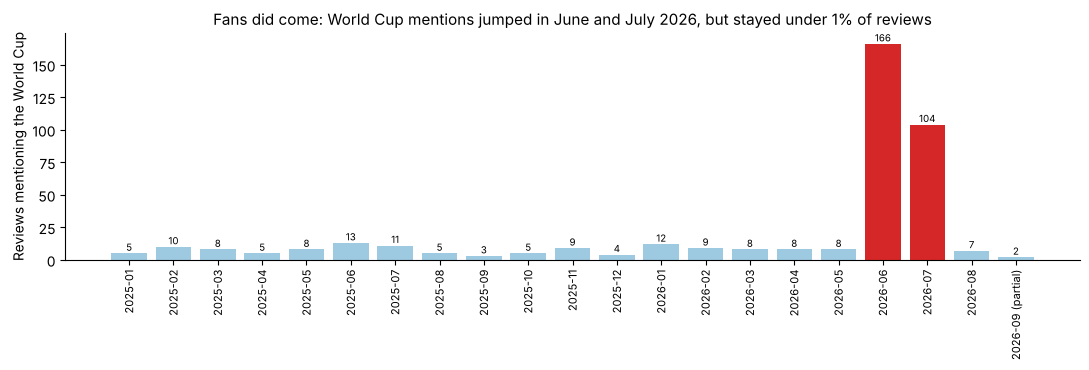

Largest monthly count before June 2026: 13


,reviews,fan_mentions,share
month,,,
2026-04,20484,8,0.000
2026-05,19339,8,0.000
2026-06,17815,166,0.009
2026-07,17554,104,0.006
2026-08,14957,7,0.000
2026-09,7077,2,0.000


In [18]:
rv["fan_mention"] = rv["comments"].str.contains(FAN, case=False, na=False)
rv["month"] = rv["date"].dt.to_period("M")
monthly = rv[rv.date >= "2025-01-01"].groupby("month").agg(reviews=("listing_id", "size"),
                                                           fan_mentions=("fan_mention", "sum"))
monthly["share"] = monthly["fan_mentions"] / monthly["reviews"]

fig, ax = plt.subplots(figsize=(11, 3.8))
labels = [str(m) + (" (partial)" if str(m) == "2026-09" else "") for m in monthly.index]
ax.bar(labels, monthly["fan_mentions"],
       color=["#D62728" if str(m) in ("2026-06", "2026-07") else "#9ECAE1" for m in monthly.index])
for i, v in enumerate(monthly["fan_mentions"]):
    ax.text(i, v + 2, int(v), ha="center", fontsize=7)
ax.set_ylabel("Reviews mentioning the World Cup")
ax.set_title("Fans did come: World Cup mentions jumped in June and July 2026, but stayed under 1% of reviews", fontsize=11)
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_2_fan_mentions.png", dpi=150)
plt.show()
print("Largest monthly count before June 2026:", monthly.loc[:"2026-05", "fan_mentions"].max())
monthly.loc["2026-04":"2026-09"]

In [19]:
wc = rv[(rv.date >= "2026-06-13") & (rv.date <= "2026-08-02")]
by_band = wc.groupby("stadium_band", observed=False).agg(reviews=("listing_id", "size"), fan_mentions=("fan_mention", "sum"))
by_band["share"] = by_band["fan_mentions"] / by_band["reviews"]
print("Jun 13 to Aug 2, 2026: share of reviews mentioning the World Cup (all listings)")
print(by_band.reindex(BANDS).to_string(formatters={"share": "{:.1%}".format}))
print(f"All bands: {wc.fan_mention.sum()} of {len(wc):,} ({wc.fan_mention.mean():.1%})\n")
for text in wc.loc[wc.fan_mention, "comments"].sample(4, random_state=RANDOM_STATE):
    print("-", text[:150].replace("\u2014", ", ").replace("\u2013", "-"), "...")   # guest text; dashes swapped for the house style

Jun 13 to Aug 2, 2026: share of reviews mentioning the World Cup (all listings)
              reviews  fan_mentions share
stadium_band                             
0-10 mi         11516           170  1.5%
10-15 mi         8645            47  0.5%
15-20 mi         6557            27  0.4%
20+ mi           3990            22  0.6%
All bands: 266 of 30,708 (0.9%)

- We stayed at Annie’s beautiful place when we visited the area for the World Cup.  We really enjoyed the pool, hot tub, and the waterfront scenery!  Ou ...
- We had a wonderful stay at Daniel’s house.  It was a perfect fit for our family of four adults, three children, and our dog, there was plenty of space  ...
- Jose had a nice place with a lot of options to eat nearby! The beach was super close and we loved the back yard with all the World Cup decor and the p ...
- Absolutely loved our stay ! My 3 and 7 years old kids loved it and had so much fun. The pool was the perfect place to relax every day. The host was in ...


The keyword count is a **lower bound** on fan stays: most guests never say why they came.

**Did international guests come?** Fans from abroad might review less often, which would make reviews undercount them. We cannot measure how often anyone reviews, but we can see whether the language mix shifted, using January to May as a check that nothing else changed. Language is not nationality (many Spanish reviews come from US residents), so a shift would only be consistent with more international guests, not proof.

In [20]:
rows = []
for year in [2025, 2026]:
    for label, a, b in [("Jan to May", "01-01", "05-31"), ("Jun 13 to Aug 2", "06-13", "08-02")]:
        w = rv[(rv.date >= f"{year}-{a}") & (rv.date <= f"{year}-{b}")]
        non_en = w["language"].isin(["es", "pt", "fr", "de", "other"])
        rows.append({"window": label, "year": year, "reviews": len(w), "not in English (all)": non_en.mean(),
                     "not in English (0-10 mi)": non_en[w.stadium_band == "0-10 mi"].mean()})
pd.DataFrame(rows).set_index(["window", "year"]).round(3)

,,reviews,not in English (all),not in English (0-10 mi)
window,year,,,
Jan to May,2025,83017,0.093,0.146
Jun 13 to Aug 2,2025,25408,0.113,0.180
Jan to May,2026,104946,0.097,0.144
Jun 13 to Aug 2,2026,30708,0.138,0.213


### What 5.2 shows


- **Fans came, but were few in the reviews:** reviews mentioning the World Cup went from at most 13 a month before June 2026 to 166 in June and 104 in July. In the tournament review window (Jun 13 to Aug 2) they were 0.9% of all reviews and 1.5% within 10 miles. This is a lower bound, since most guests never say why they came.
- **No extra reviews near the stadium:** on the same 8,480 established listings, reviews in the tournament window were 3.5% above the same dates in 2025 within 10 miles, against 1.4% above in January to May: a change of +2.1 points. The far north (20+ miles) grew most, from 3.6% below 2025 in January to May to 7.1% above (+10.7 points). The 10 to 15 and 15 to 20 mile bands moved by less than 1 point, so against the middle of the county the near band was about 2 points stronger, and against the far north about 9 points weaker. The far north had a weak 2025 summer (see the 2025 check), so part of its 2026 gain may be a rebound. Either way, there is no large World Cup lift in reviews.
- **More non-English reviews:** in the tournament window the share of reviews not in English rose from 11.3% (2025) to 13.8% (2026), and from 18.0% to 21.3% within 10 miles, while January to May barely moved (9.3% to 9.7%). This is consistent with more international guests, not proof: language is not nationality.
- **Market size, for context:** listings grew 7.3% from Dec 2025 to Sep 2026 and active listings 4.8%. This is the whole market, not a World Cup effect.
- **The 2025 baseline:** Hard Rock Stadium hosted 8 Club World Cup matches in June 2025. The same test one year earlier (summer 2025 vs 2024, against January to May) shows no near-stadium bump in 2025: reviews within 10 miles rose 5.1 points more than in January to May, about the same as 10 to 15 miles (+4.8) and less than 15 to 20 miles (+8.0), while the far north rose only 1.6. So the 2025 Club World Cup does not explain the flat 2026 result near the stadium.
- **Meaning:** fans showed up, but total reviews near the stadium did not rise more than usual. Either fan stays replaced some normal summer stays, or fans reviewed less. Section 5.3 checks bookings directly.

## 5.3 Were nights booked, and at what price?

Each scrape shows every one of the next 365 nights as open or taken ("taken" = booked or blocked by the host; the calendar cannot tell those apart). Three scrapes saw the tournament nights before they happened: **Dec 28, 2025, Mar 30, 2026 and Jun 29, 2026** (the June scrape ran Jun 29 to Jul 3, so each listing's calendar starts on its own scrape day, and the June group-stage nights are already past).

**Method: difference-in-differences (DiD), from the correlation vs causation lecture.** Listings near the stadium can be busier for reasons unrelated to soccer (beach towns, newer listings), so we never compare near and far directly. We compare **how much more tournament nights were taken than ordinary nights, near the stadium vs far away**:

> World Cup effect = (near: tournament nights minus ordinary nights) minus (far: tournament nights minus ordinary nights)

- **Near** = within 10 miles of Hard Rock Stadium (mostly Hollywood and Hallandale Beach); **far** = more than 20 miles (mostly Pompano and Deerfield Beach).
- **Tournament nights** = Jun 11 to Jul 19; **ordinary nights** = the other nights in the window. **Match nights** are tested on top of the tournament effect.
- The model is a **linear probability model**: linear regression on a 0/1 outcome (taken or not), so effects read directly as percentage points. Day-of-week dummies keep Fridays and Saturdays from looking like soccer. Standard errors are clustered by host.
- **The key assumption** is that without the World Cup, near and far nights would have moved alike. We test it with **placebo windows**: the same comparison run on blocks of ordinary nights that had no tournament. If those show "effects" as large as the real one, the real one is not believable.
- Mid-term rentals (30+ night minimum) are left out.

In [21]:
cal = pd.read_parquet(DATA / "calendar_worldcup_window.parquet")

def info(snapshot):
    return listings[listings.snapshot_date == snapshot].set_index("id")[["stadium_band", "mid_term", "host_id"]]

def tag(x):
    x["near"] = (x.stadium_band == "0-10 mi").astype(int)
    x["tournament"] = x.date.between(*TOURNAMENT).astype(int)
    x["weekday"] = x.date.dt.day_name()
    x["night_type"] = np.select([x.match_day == 1, x.tournament == 1],
                                ["match night", "other tournament night"], "ordinary night")
    return x

def near_far(x, y):
    t = x.pivot_table(index="night_type", columns="near", values=y, aggfunc="mean")
    t.columns = ["far (20+ mi)", "near (0-10 mi)"]
    return t.reindex(["ordinary night", "other tournament night", "match night"])

DID = "{y} ~ near * tournament + near * match_day + C(weekday)"
def did(x, y, extra=""):
    m = clustered(DID.format(y=y) + extra, x, "host_id")
    return pd.DataFrame({k: effect(m, t, 100) for k, t in
                         [("tournament night", "near:tournament"), ("match night, on top", "near:match_day")]}).T

def did_listing_fe(x, y):
    # Same model with listing fixed effects: subtract each listing's own average from every
    # variable (the "within" transformation), so each listing is compared only with itself
    x = x.copy()
    x["near_tournament"], x["near_match"] = x.near * x.tournament, x.near * x.match_day
    wd = pd.get_dummies(x.weekday, drop_first=True, dtype=float)
    cols = [y, "tournament", "match_day", "near_tournament", "near_match"] + list(wd.columns)
    z = pd.concat([x[["listing_id", "host_id"] + cols[:5]], wd], axis=1)
    z[cols] = z[cols] - z.groupby("listing_id")[cols].transform("mean")
    z.columns = [c.replace(" ", "_") for c in z.columns]
    f = f"{y} ~ 0 + " + " + ".join(c.replace(" ", "_") for c in cols[1:])
    m = clustered(f, z.reset_index(drop=True), "host_id")
    return pd.DataFrame({k: effect(m, t, 100) for k, t in
                         [("tournament night", "near_tournament"), ("match night, on top", "near_match")]}).T

def placebo(x, y, length, starts):
    # Drop the real tournament nights, pretend a block of ordinary nights was the tournament
    z = x[x.tournament == 0].copy()
    out = {}
    for s in starts:
        z["fake"] = z.date.between(pd.Timestamp(s), pd.Timestamp(s) + pd.Timedelta(days=length - 1)).astype(int)
        m = clustered(f"{y} ~ near * fake + C(weekday)", z, "host_id")
        out[f"{pd.Timestamp(s):%b %d} + {length} nights"] = effect(m, "near:fake", 100)
    return pd.DataFrame(out).T

def no_july4(d):
    return d[~d.date.between("2026-07-02", "2026-07-05")]

print("Share of June-scrape listings also found by the March scrape, by band:",
      (pd.Series(info(JUN).index.isin(info(MAR).index), index=info(JUN).index)
       .groupby(info(JUN)["stadium_band"], observed=True).mean().round(3).to_dict()))

Share of June-scrape listings also found by the March scrape, by band: {'0-10 mi': 0.457, '10-15 mi': 0.48, '15-20 mi': 0.529, '20+ mi': 0.558}


### A. What was already taken on December 28, three weeks after the draw?

Every night Jun 1 to Sep 30 in the Dec 28 calendar. Listings whose whole Jun to Jul calendar was closed are dropped: their hosts had not opened those dates yet, which says nothing about demand.

In [22]:
x = cal[cal.snapshot_date == DEC].join(info(DEC), on="listing_id")
x = x[(x.mid_term == 0) & x.stadium_band.isin(["0-10 mi", "20+ mi"])]
closed = x[x.date <= "2026-07-31"].groupby("listing_id")["unavailable"].min().loc[lambda s: s == 1].index
closed_share = x.groupby("listing_id")["stadium_band"].first().pipe(lambda b: b.index.isin(closed)).mean()
print(f"Listings with every Jun to Jul night closed (dropped): {len(closed):,} ({closed_share:.0%})")
dec_stock = tag(x[~x.listing_id.isin(closed)].copy())
print(f"{dec_stock.listing_id.nunique():,} listings, {len(dec_stock):,} nights\n")
print("Share of nights already taken on Dec 28")
print(near_far(dec_stock, "unavailable").to_string(float_format="{:.1%}".format), "\n")
did_dec = did(dec_stock, "unavailable")
print("DiD, percentage points (near minus far, tournament nights minus ordinary nights)")
print(did_dec.round(3).to_string(), "\n")
print("Same, June and July nights only (ordinary nights = Jun 1 to 10 and Jul 20 to 31)")
print(did(dec_stock[dec_stock.date <= "2026-07-31"], "unavailable").round(3).to_string(), "\n")
plac_dec = placebo(dec_stock, "unavailable", 39, ["2026-07-20", "2026-07-27", "2026-08-03", "2026-08-10", "2026-08-17", "2026-08-23"])
print("Placebo: 39-night blocks of ordinary nights treated as if they were the tournament")
plac_dec.round(3)

Listings with every Jun to Jul night closed (dropped): 1,485 (17%)


7,274 listings, 887,428 nights

Share of nights already taken on Dec 28
                        far (20+ mi)  near (0-10 mi)
night_type                                          
ordinary night                 10.9%           11.3%
other tournament night         11.2%           15.1%
match night                    11.4%           18.2% 



DiD, percentage points (near minus far, tournament nights minus ordinary nights)
                     estimate  ci low  ci high  p value
tournament night        3.560   0.822    6.298    0.011
match night, on top     2.840   1.471    4.209    0.000 

Same, June and July nights only (ordinary nights = Jun 1 to 10 and Jul 20 to 31)


                     estimate  ci low  ci high  p value
tournament night        2.922   1.142    4.702    0.001
match night, on top     2.840   1.471    4.209    0.000 



Placebo: 39-night blocks of ordinary nights treated as if they were the tournament


,estimate,ci low,ci high,p value
Jul 20 + 39 nights,1.592,-0.120,3.305,0.068
Jul 27 + 39 nights,1.179,-0.440,2.798,0.153
Aug 03 + 39 nights,1.050,-0.473,2.573,0.177
Aug 10 + 39 nights,0.686,-0.537,1.908,0.272
Aug 17 + 39 nights,0.262,-1.123,1.646,0.711
Aug 23 + 39 nights,-1.187,-3.134,0.761,0.232


### B. Later bookings: nights open in one scrape and taken by the next

For each night that was **open** in an earlier scrape, was it **taken** in the later one? Only open nights count, so nights a host had closed early do not enter. Three pairs of scrapes:
- **Dec to Mar** (nights Jun 1 to Sep 30). Uses the partial March scrape, so only listings found by both.
- **Mar to Jun** and **Dec to Jun** (nights Jun 29 to Sep 30, because the June calendar starts then). Dec to Jun does not use March at all.

Checks for the June pairs:
1. Nights 0 to 1 days after each listing's own June scrape day are dropped (nights right after a scrape read as taken almost regardless).
2. **Without Jul 2 to 5**, because the Jul 3 match night is also the start of the July 4th weekend.
3. **Listing fixed effects:** each listing compared only with itself.
4. **A near-specific lead-time trend:** tournament nights are closer to the June scrape than August nights, so if near and far listings fill short-notice nights differently, the DiD would pick that up. Adding `near x days ahead` tests this.
5. **Placebo windows** of 21 ordinary nights (the length of the visible tournament, Jun 29 to Jul 19). These start on Jul 20 or later, so they only test nights booked further ahead.

**Important:** in the June scrape the tournament nights are also the shortest-notice nights (0 to 20 days ahead). Checks 3 to 5 do not separate the tournament from a general short-notice difference between near and far listings; check 6 below tries, but it is weak.

In [23]:
def flows(early, late, start, end):
    e = (cal[(cal.snapshot_date == early) & cal.date.between(start, end)]
         .set_index(["listing_id", "date"])["unavailable"].rename("taken_early"))
    l = (cal[(cal.snapshot_date == late) & cal.date.between(start, end)]
         .set_index(["listing_id", "date"])[["unavailable", "match_day", "days_ahead"]])
    x = l.join(e, how="inner").reset_index()
    x = x[(x.taken_early == 0) & (x.days_ahead >= 2)].join(info(late), on="listing_id")
    x = x[(x.mid_term == 0) & x.stadium_band.isin(["0-10 mi", "20+ mi"])].copy()
    x["taken"] = x["unavailable"]
    return tag(x)

dec_mar = flows(DEC, MAR, "2026-06-01", "2026-09-30")
mar_jun = flows(MAR, JUN, "2026-06-29", "2026-09-30")
dec_jun = flows(DEC, JUN, "2026-06-29", "2026-09-30")
for name, d in [("Dec to Mar", dec_mar), ("Mar to Jun", mar_jun), ("Dec to Jun", dec_jun)]:
    print(f"{name}: share of open nights that got taken ({d.listing_id.nunique():,} listings, {len(d):,} nights)")
    print(near_far(d, "taken").to_string(float_format="{:.1%}".format), "\n")

LEAD = " + days_ahead + near:days_ahead"
later = pd.concat({
    "Dec to Mar": did(dec_mar, "taken"),
    "Dec to Mar, without Jul 2 to 5": did(no_july4(dec_mar), "taken"),
    "Mar to Jun": did(mar_jun, "taken"),
    "Mar to Jun, without Jul 2 to 5": did(no_july4(mar_jun), "taken"),
    "Mar to Jun, listing fixed effects": did_listing_fe(mar_jun, "taken"),
    "Mar to Jun, near-specific lead-time trend": did(mar_jun, "taken", LEAD),
    "Mar to Jun, nights Jun 29 to Jul 31 only": did(mar_jun[mar_jun.date <= "2026-07-31"], "taken"),
    "Mar to Jun, Jun 29 to Jul 31 only, lead-time trend": did(mar_jun[mar_jun.date <= "2026-07-31"], "taken", LEAD),
    "Dec to Jun (no March)": did(dec_jun, "taken"),
    "Dec to Jun, without Jul 2 to 5": did(no_july4(dec_jun), "taken"),
    "Dec to Jun, near-specific lead-time trend": did(dec_jun, "taken", LEAD),
})
later.round(3)

Dec to Mar: share of open nights that got taken (4,209 listings, 445,252 nights)
                        far (20+ mi)  near (0-10 mi)
night_type                                          
ordinary night                  9.5%           18.1%
other tournament night         16.3%           25.1%
match night                    18.1%           28.0% 

Mar to Jun: share of open nights that got taken (4,322 listings, 344,628 nights)
                        far (20+ mi)  near (0-10 mi)
night_type                                          
ordinary night                 16.4%           15.7%
other tournament night         42.6%           34.4%
match night                    53.1%           47.0% 

Dec to Jun: share of open nights that got taken (5,450 listings, 458,828 nights)
                        far (20+ mi)  near (0-10 mi)
night_type                                          
ordinary night                 21.8%           20.9%
other tournament night         47.7%           38.4%
match night

estimate  ci low  ci high  p value
Dec to Mar                                         tournament night        0.165  -2.060    2.390    0.884
                                                   match night, on top     1.082   0.208    1.957    0.015
Dec to Mar, without Jul 2 to 5                     tournament night        0.194  -2.025    2.413    0.864
                                                   match night, on top     1.367   0.451    2.282    0.003
Mar to Jun                                         tournament night       -7.480 -10.584   -4.376    0.000
                                                   match night, on top     2.065  -0.215    4.344    0.076
Mar to Jun, without Jul 2 to 5                     tournament night       -7.058 -10.226   -3.890    0.000
                                                   match night, on top     0.712  -1.790    3.215    0.577
Mar to Jun, listing fixed effects                  tournament night       -7.731 -10.830   -4.631    0.000
                                                   match night, on top     1.820  -0.443    4.083    0.115
Mar to Jun, near-specific lead-time trend          tournament night       -7.786 -11.081   -4.491    0.000
                                                   match night, on top     2.035  -0.247    4.317    0.080
Mar to Jun, nights Jun 29 to Jul 31 only           tournament night       -5.519  -8.660   -2.378    0.001
                                                   match night, on top     2.011  -0.265    4.286    0.083
Mar to Jun, Jun 29 to Jul 31 only, lead-time trend tournament night       -2.768  -7.154    1.618    0.216
                                                   match night, on top     1.812  -0.475    4.099    0.121
Dec to Jun (no March)                              tournament night       -8.298 -11.763   -4.834    0.000
                                                   match night, on top     1.567  -0.460    3.593    0.130
Dec to Jun, without Jul 2 to 5                     tournament night       -8.435 -11.965   -4.904    0.000
                                                   match night, on top    -0.201  -2.354    1.952    0.855
Dec to Jun, near-specific lead-time trend          tournament night       -8.871 -12.942   -4.800    0.000
                                                   match night, on top     1.532  -0.492    3.556    0.138

In [24]:
plac_mar_jun = placebo(mar_jun, "taken", 21, ["2026-07-20", "2026-07-27", "2026-08-03", "2026-08-10", "2026-08-17",
                                              "2026-08-24", "2026-08-31", "2026-09-07"])
plac_dec_mar = placebo(dec_mar, "taken", 39, ["2026-07-20", "2026-07-27", "2026-08-03", "2026-08-10", "2026-08-17", "2026-08-23"])
print("Placebo, Mar to Jun (real tournament estimate:", round(later.loc[('Mar to Jun', 'tournament night'), 'estimate'], 2), ")")
print(plac_mar_jun.round(3).to_string(), "\n")
print("Placebo, Dec to Mar (real tournament estimate:", round(later.loc[('Dec to Mar', 'tournament night'), 'estimate'], 2), ")")
print(plac_dec_mar.round(3).to_string())

Placebo, Mar to Jun (real tournament estimate: -7.48 )
                    estimate  ci low  ci high  p value
Jul 20 + 21 nights    -0.702  -3.096    1.691    0.565
Jul 27 + 21 nights     2.289   0.437    4.141    0.015
Aug 03 + 21 nights     2.400   0.826    3.973    0.003
Aug 10 + 21 nights     2.487   1.021    3.952    0.001
Aug 17 + 21 nights     0.760  -0.623    2.143    0.281
Aug 24 + 21 nights     0.180  -1.229    1.590    0.802
Aug 31 + 21 nights    -0.547  -2.157    1.063    0.505
Sep 07 + 21 nights    -0.902  -2.686    0.883    0.322 

Placebo, Dec to Mar (real tournament estimate: 0.17 )
                    estimate  ci low  ci high  p value
Jul 20 + 39 nights    -0.121  -1.558    1.317    0.869
Jul 27 + 39 nights     0.122  -1.362    1.607    0.872
Aug 03 + 39 nights     0.487  -0.842    1.816    0.472
Aug 10 + 39 nights     0.485  -0.799    1.769    0.459
Aug 17 + 39 nights     0.148  -1.187    1.484    0.828
Aug 23 + 39 nights     0.555  -0.961    2.070    0.473


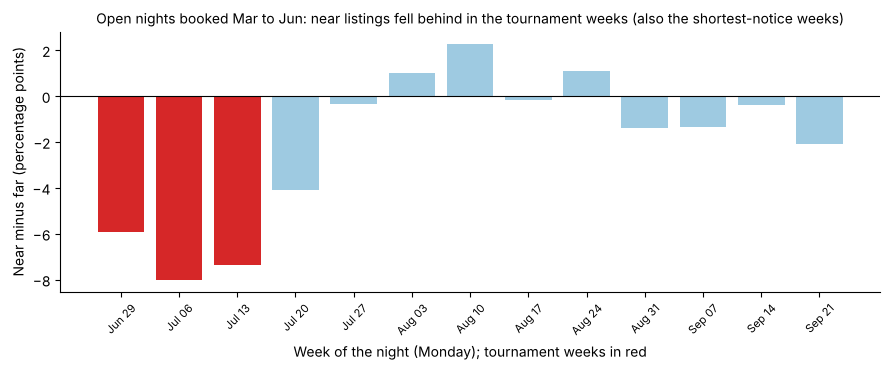

near,0,1,near minus far (points)
week,,,
2026-06-29,0.675,0.616,-5.908
2026-07-06,0.410,0.330,-8.004
2026-07-13,0.363,0.290,-7.349
2026-07-20,0.345,0.304,-4.109
2026-07-27,0.269,0.265,-0.354
2026-08-03,0.216,0.226,0.997
2026-08-10,0.167,0.190,2.287
2026-08-17,0.157,0.155,-0.154
2026-08-24,0.115,0.126,1.092


In [25]:
mar_jun["week"] = mar_jun["date"] - pd.to_timedelta(mar_jun["date"].dt.weekday, unit="D")
weekly = mar_jun.groupby(["week", "near"])["taken"].mean().unstack()
weekly["near minus far (points)"] = (weekly[1] - weekly[0]) * 100
weekly = weekly[weekly.index <= "2026-09-21"]
labels = [f"{w:%b %d}" for w in weekly.index]
tour_weeks = [w <= pd.Timestamp("2026-07-19") for w in weekly.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(labels, weekly["near minus far (points)"], color=["#D62728" if t else "#9ECAE1" for t in tour_weeks])
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Week of the night (Monday); tournament weeks in red")
ax.set_ylabel("Near minus far (percentage points)")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.set_title("Open nights booked Mar to Jun: near listings fell behind in the tournament weeks (also the shortest-notice weeks)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_3_weekly_gap.png", dpi=150)
plt.show()
weekly.round(3)

**Check 6: is it the tournament, or do near listings always fill short-notice nights worse?** In the June scrape every visible tournament night is 0 to 20 days away, so a general habit (for example, far-north listings getting more last-minute bookings) would look the same. The daily calendar only covers the summer, so this check uses `calendar_monthly`: for each pair of scrapes, the change in the share of a month's nights taken, near minus far, in the **first full month after the later scrape** (short notice) vs the **next three months**. Only April 2026 and October 2026 are short-notice months without a tournament. Listings whose month was fully closed in the earlier scrape are left out.

In [26]:
cm = pd.read_parquet(DATA / "calendar_monthly.parquet")
rows = []
for early, late in [(DEC, MAR), (MAR, JUN), (DEC, JUN), (JUN, SEP)]:
    a = cm[cm.snapshot_date == early].set_index(["listing_id", "month"])["unavailable_share"].rename("before")
    b = cm[cm.snapshot_date == late].set_index(["listing_id", "month"])[["unavailable_share", "days"]]
    x = b.join(a, how="inner").reset_index().join(info(late), on="listing_id")
    x = x[(x.days >= 25) & (x.mid_term == 0) & x.stadium_band.isin(["0-10 mi", "20+ mi"]) & (x.before < 1)]
    x["change"] = x.unavailable_share - x.before
    months = sorted(x.month.unique())[:4]
    gap = {m: (x[x.month == m].groupby("stadium_band", observed=True)["change"].mean()
               .pipe(lambda g: (g["0-10 mi"] - g["20+ mi"]) * 100)) for m in months}
    rows.append({"scrapes": f"{early:%b %Y} to {late:%b %Y}", "short-notice month": months[0],
                 "near minus far, short-notice month": gap[months[0]],
                 "near minus far, next 3 months (average)": np.mean([gap[m] for m in months[1:]]),
                 "tournament in short-notice month": "yes" if months[0] == "2026-07" else "no"})
lead_check = pd.DataFrame(rows).set_index("scrapes")
lead_check["difference (points)"] = lead_check.iloc[:, 1] - lead_check.iloc[:, 2]
lead_check.round(1)

,short-notice month,"near minus far, short-notice month","near minus far, next 3 months (average)",tournament in short-notice month,difference (points)
scrapes,,,,,
Dec 2025 to Mar 2026,2026-04,2.200,6.900,no,-4.700
Mar 2026 to Jun 2026,2026-07,-7.400,-1.300,yes,-6.200
Dec 2025 to Jun 2026,2026-07,-8.800,-0.500,yes,-8.200
Jun 2026 to Sep 2026,2026-10,0.300,-2.600,no,2.900


**Did near-stadium hosts block nights early and release them later?** If hosts held tournament nights back (marked unavailable) to sell later at a higher price, the December "taken" numbers would overstate early bookings. Check: nights taken in one scrape that were open again in the next. Held nights would reopen more often near the stadium.

In [27]:
def reopened(early, late, start, end):
    # Nights taken in the earlier scrape: share open again in the later one, by band and night type
    e = cal[(cal.snapshot_date == early) & cal.date.between(start, end)].set_index(["listing_id", "date"])["unavailable"].rename("early")
    l = cal[(cal.snapshot_date == late) & cal.date.between(start, end)].set_index(["listing_id", "date"])["unavailable"].rename("late")
    r = l.to_frame().join(e, how="inner").reset_index().join(info(late), on="listing_id")
    r = r[(r.mid_term == 0) & (r.early == 1) & r.stadium_band.isin(["0-10 mi", "20+ mi"])]
    r["night"] = np.select([r.date.isin(cal.loc[cal.match_day == 1, "date"].unique()), r.date.between(*TOURNAMENT)],
                           ["match nights", "other tournament nights"], "ordinary nights")
    return (1 - r.pivot_table(index="night", columns="stadium_band", values="late", aggfunc="mean", observed=True)).round(3)
print("Nights Jun 1 to Sep 30 taken on Dec 28 that were open again on Mar 30:")
print(reopened(DEC, MAR, "2026-06-01", "2026-09-30").to_string(), "\n")
print("Nights Jun 29 to Sep 30 taken on Mar 30 that were open again on Jun 29:")
print(reopened(MAR, JUN, "2026-06-29", "2026-09-30").to_string())

Nights Jun 1 to Sep 30 taken on Dec 28 that were open again on Mar 30:


stadium_band             0-10 mi  20+ mi
night                                   
match nights               0.332   0.397
ordinary nights            0.440   0.414
other tournament nights    0.373   0.408 

Nights Jun 29 to Sep 30 taken on Mar 30 that were open again on Jun 29:


stadium_band             0-10 mi  20+ mi
night                                   
match nights               0.200   0.241
ordinary nights            0.423   0.445
other tournament nights    0.269   0.290


### C. Prices

Same listings in the March, June and September scrapes (short-term, believable prices). Inside Airbnb records the nightly price shown on the listing page when it was scraped, without saying which stay dates it is for; in practice it is the price for near-term dates. The scrapes fell around Easter (Mar 30 to Apr 2), the July 4th week (Jun 29 to Jul 3) and late September (Sep 23 to 26), so seasonal pricing that differs between Hollywood and Pompano could look like a World Cup effect, and December has no prices to test that against. Changes are in log points (0.10 log points is about 10.5%); the tables also convert them to percent.

Check: the same comparison with **price spikes kept** (`price_spike`), because 46 of the 48 June spikes are upward and some are real World Cup pricing.

In [28]:
def price_panel(rows):
    p = rows.pivot_table(index="id", columns="snapshot_date", values="price")
    p.columns = ["mar", "jun", "sep"]
    p = p.dropna().join(info(JUN)[["stadium_band", "host_id"]])
    for a, b in [("mar", "jun"), ("jun", "sep"), ("mar", "sep")]:
        p[f"{a}_to_{b}"] = np.log(p[b] / p[a])
    return p

base = listings[listings.snapshot_date.isin([MAR, JUN, SEP]) & (listings.mid_term == 0) & listings.price.notna()]
px = price_panel(base[base.price_outlier == 0])
px_spikes = price_panel(base[base.price_implausible == 0])
CHANGES = ["mar_to_jun", "jun_to_sep", "mar_to_sep"]
print(f"{len(px):,} listings with a price in all three scrapes ({len(px_spikes):,} with spikes kept)\n")
summary = px.groupby("stadium_band", observed=True)[CHANGES].agg(["mean", "median"])
print("Price change by band, percent (from the mean and the median log change)")
print((np.exp(summary) - 1).mul(100).round(1).to_string(), "\n")

def price_did(p):
    two = p[p.stadium_band.isin(["0-10 mi", "20+ mi"])].assign(near=lambda d: (d.stadium_band == "0-10 mi").astype(int)).reset_index()
    t = pd.DataFrame({c: effect(clustered(f"{c} ~ near", two, "host_id"), "near") for c in CHANGES}).T
    t["as percent"] = (np.exp(t["estimate"]) - 1) * 100
    return t
price_table = pd.concat({"main sample": price_did(px), "price spikes kept": price_did(px_spikes)})
print("Near minus far price change (log points; 'as percent' converts the estimate)")
price_table.round(3)

7,344 listings with a price in all three scrapes (7,369 with spikes kept)

Price change by band, percent (from the mean and the median log change)
             mar_to_jun        jun_to_sep         mar_to_sep        
                   mean median       mean  median       mean  median
stadium_band                                                        
0-10 mi          -2.700  0.000    -16.400 -14.100    -18.700 -16.100
10-15 mi         -8.800 -5.000    -10.600 -10.100    -18.500 -15.400
15-20 mi         -8.500 -6.900     -9.300  -8.100    -17.000 -13.500
20+ mi           -7.400 -5.300     -8.900  -8.300    -15.700 -13.200 



Near minus far price change (log points; 'as percent' converts the estimate)


estimate  ci low  ci high  p value  as percent
main sample       mar_to_jun     0.050   0.024    0.076    0.000       5.129
                  jun_to_sep    -0.086  -0.113   -0.059    0.000      -8.275
                  mar_to_sep    -0.036  -0.068   -0.004    0.026      -3.570
price spikes kept mar_to_jun     0.060   0.032    0.088    0.000       6.165
                  jun_to_sep    -0.095  -0.122   -0.068    0.000      -9.078
                  mar_to_sep    -0.035  -0.069   -0.002    0.037      -3.472

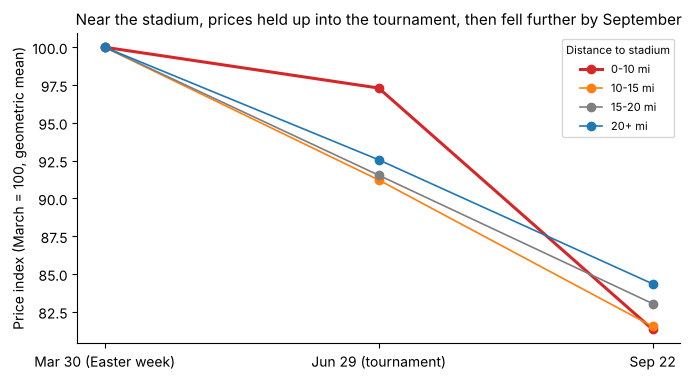

In [29]:
fig, ax = plt.subplots(figsize=(7, 3.9))
for band in BANDS:
    m = np.exp(px[px.stadium_band == band][["mar_to_jun", "mar_to_sep"]].mean())
    ax.plot(["Mar 30 (Easter week)", "Jun 29 (tournament)", "Sep 22"], [100, 100 * m["mar_to_jun"], 100 * m["mar_to_sep"]],
            marker="o", color=BAND_COLORS[band], label=band, lw=2.2 if band == "0-10 mi" else 1.2)
ax.set_ylabel("Price index (March = 100, geometric mean)")
ax.set_title("Near the stadium, prices held up into the tournament, then fell further by September", fontsize=11)
ax.legend(title="Distance to stadium", fontsize=8, title_fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG / "5_3_prices.png", dpi=150)
plt.show()

**Did raising prices cost bookings?** Within each band, listings that raised their price more than 5% from March to June vs the rest, on the share of their open tournament nights (Jun 29 to Jul 19, open in March) that got taken by June, holding listing traits constant. Only listings with 5+ such open nights. An association only: hosts who raised prices may differ in other ways, and the June price is the listing-page price on the scrape day, which can depend on which nights were still unsold, so the link could run both ways.

In [30]:
ctrl = june.set_index("id")[["bedrooms", "entire_home", "single_host", "small_host", "superhost", "log_reviews"]]
fill = (mar_jun[mar_jun.tournament == 1].groupby("listing_id")["taken"].agg(open_nights="size", fill="mean"))
lf = px.join(fill[fill.open_nights >= 5], how="inner").join(ctrl, how="inner").reset_index()
lf["raised_price"] = (lf["mar_to_jun"] > np.log(1.05)).astype(int)
rows = {}
for band in ["0-10 mi", "20+ mi"]:
    d = lf[lf.stadium_band == band]
    m = clustered("fill ~ raised_price + bedrooms + entire_home + single_host + small_host + superhost + log_reviews", d, "host_id")
    raw = d.groupby("raised_price")["fill"].mean()
    rows[band] = {"listings": len(d), "share that raised": d.raised_price.mean(), "fill if raised": raw.get(1),
                  "fill if not": raw.get(0), **effect(m, "raised_price", 100)}
raise_table = pd.DataFrame(rows).T
raise_table.round(3)

,listings,share that raised,fill if raised,fill if not,estimate,ci low,ci high,p value
0-10 mi,"2,320.000",0.331,0.324,0.377,-5.248,-8.220,-2.277,0.001
20+ mi,"1,047.000",0.239,0.459,0.440,3.262,-2.462,8.985,0.264


### D. Minimum stays around matches

In [31]:
ms = cal[cal.snapshot_date.isin([MAR, JUN]) & cal.date.between("2026-07-01", "2026-07-31")].join(info(JUN)[["stadium_band", "mid_term"]], on="listing_id")
ms = ms[(ms.mid_term == 0) & ms.stadium_band.isin(["0-10 mi", "20+ mi"])]
ms["night"] = np.where(ms.match_day == 1, "match night", "other July night")
ms.pivot_table(index=["snapshot_date", "night"], columns="stadium_band", values="minimum_nights", aggfunc="mean", observed=True).round(2)

stadium_band                    0-10 mi  20+ mi
snapshot_date night                            
2026-03-30    match night         3.570   3.020
              other July night    3.500   2.940
2026-06-29    match night         3.420   3.420
              other July night    3.530   3.350

### What 5.3 shows


- **Early demand, right after the draw:** on Dec 28, three weeks after the Dec 5 draw, near-stadium listings already had **about 3 points** more of their tournament nights taken than far listings, relative to ordinary nights (2.9, CI 1.1 to 4.7, on June and July nights; 3.6, CI 0.8 to 6.3, on June to September nights), plus **2.8 points** more on match nights (CI 1.5 to 4.2). Near match nights were 18.2% taken vs 11.3% for near ordinary nights; far listings showed 11.4% vs 10.9%. The placebo windows range from -1.2 to +1.6, so the early signal stands out.
- **These look like real bookings, not holds:** from December to March, near-stadium hosts reopened more of their taken ordinary nights than far hosts (44.0% vs 41.4%) but fewer of their taken tournament nights (37.3% vs 40.8%) and match nights (33.2% vs 39.7%). Holding tournament nights back for later sale would show the opposite. From March to June, near hosts reopened slightly fewer nights of every kind (ordinary 42.3% vs 44.5%, other tournament 26.9% vs 29.0%, match 20.0% vs 24.1%).
- **Little after that:** from December to March, near listings added no extra tournament bookings (+0.2, p 0.88), and match nights +1.1 points (p 0.015).
- **No sign of a late World Cup rush near the stadium.** From March to June, near listings' open tournament nights got taken 7.5 points less often than far listings', relative to ordinary nights (raw estimate, 95% CI -10.6 to -4.4; -7.1 without Jul 2 to 5, -7.7 with listing fixed effects, -8.3 from December). But in the June scrape the tournament nights were also the shortest-notice nights, and the checks that hold (placebo windows, the full-window lead-time trend) only test nights booked further ahead. With a lead-time trend in the June and July window the gap shrinks to -2.8 (p 0.22), and short-notice months without a tournament swing both ways (April 2026 -4.7, October +2.9). So the shortfall cannot be separated from normal short-notice and seasonal differences; the safe conclusion is that there was no late rush.
- **Match nights in early July cannot be separated from the July 4th weekend:** without Jul 2 to 5 the match-night effect is +0.7 (p 0.58).
- **Prices held up, then fell:** from March to June, near listings cut prices less: -2.7% on average (median 0.0%) vs -7.4% far (median -5.3%), a difference of about +5.1% (+5.0 log points, CI +2.4 to +7.6). By September they fell more: -16.4% vs -8.9%, a difference of about -8.3%, and ended 3.6% below far listings relative to March (p 0.026). With price spikes kept: +6.2% and -9.1%. The March and June scrapes fell on Easter week and the July 4th week, so seasonal pricing that differs between Hollywood and Pompano could explain part of this.
- **Higher prices, fewer bookings near the stadium:** within 10 miles, the third of listings that raised prices more than 5% from March to June filled 32.4% of their open tournament nights vs 37.7% for the rest (adjusted -5.2 points, CI -8.2 to -2.3). Far away the difference was +3.3 (p 0.26). An association only: the June price is the scrape-day listing price, which can depend on which nights were still unsold.
- **No minimum-stay premium on match nights:** match nights carried the same minimum stay as other July nights (within about 0.1 night), near and far.

## 5.4 Did the bet pay for the hosts who rebranded?

Rebranded listings vs **comparable** listings that did not rebrand: same distance band, bedrooms, room type, host type, Superhost status and past reviews (before June 1). One regression per outcome; standard errors clustered by host.

**The key test is before vs during.** Hosts who bothered to rebrand may simply be more active hosts. Most rebranding happened between March (65 titles) and June (483). So we also measure the same outcome **before** the tournament (Jan to May 2026 vs Jan to May 2025). If rebranders were already ahead then, a gap during the tournament is not evidence that rebranding worked. The cleanest estimate is the **change in the gap**: (tournament reviews vs last year) minus (Jan to May reviews vs last year). Review counts are logged as log(count + 1), so coefficients are differences in log points, not percents; raw averages are shown next to them.

In [32]:
rv_l = rv[["listing_id", "date", "fan_mention"]]
def count(a, b, fan=False):
    w = rv_l[(rv_l.date >= a) & (rv_l.date <= b)]
    return (w[w.fan_mention] if fan else w).groupby("listing_id").size()

bet = june.set_index("id").copy()
for name, (a, b) in {"tour26": ("2026-06-13", "2026-08-02"), "tour25": ("2025-06-13", "2025-08-02"),
                     "jm26": ("2026-01-01", "2026-05-31"), "jm25": ("2025-01-01", "2025-05-31")}.items():
    bet[name] = count(a, b).reindex(bet.index).fillna(0)
    bet["log_" + name] = np.log1p(bet[name])
bet["fan_review"] = (count("2026-06-13", "2026-08-02", fan=True).reindex(bet.index).fillna(0) > 0).astype(int)
bet["still_listed_sep"] = bet.index.isin(in_sep).astype(int)
bet["change_gap"] = (bet.log_tour26 - bet.log_tour25) - (bet.log_jm26 - bet.log_jm25)
bet = bet.join(px[["mar_to_jun", "jun_to_sep"]]).join(fill[fill.open_nights >= 5]["fill"])
bet["stadium_band"] = bet["stadium_band"].astype(str)   # so subsets with fewer bands get no empty dummy columns

CONTROLS = "C(stadium_band) + bedrooms + entire_home + single_host + small_host + superhost + log_reviews"
outcomes = [
    ("Reviews Jun 13 to Aug 2 2026 (log), given same dates 2025", "log_tour26", " + log_tour25", "ols"),
    ("BEFORE: reviews Jan to May 2026 (log), given Jan to May 2025", "log_jm26", " + log_jm25", "ols"),
    ("Change in the gap: tournament minus Jan to May (log)", "change_gap", "", "ols"),
    ("Price change Mar to Jun (log)", "mar_to_jun", "", "ols"),
    ("Price change Jun to Sep (log)", "jun_to_sep", "", "ols"),
    ("Open tournament nights taken, Mar to Jun (share; 0-10 and 20+ mi only)", "fill", "", "ols"),
    ("At least one World Cup review (odds ratio)", "fan_review", "", "logit"),
    ("Still listed in September (odds ratio)", "still_listed_sep", "", "logit"),
]
rows = []
for label, y, extra, kind in outcomes:
    d = bet.dropna(subset=[y]).reset_index()
    m = clustered(f"{y} ~ rebranded + {CONTROLS}{extra}", d, "host_id", kind)
    e = effect(m, "rebranded")
    if kind == "logit":
        e = {k: (np.exp(v) if k != "p value" else v) for k, v in e.items()}
    rows.append({"outcome": label, "listings": len(d), "rebranded listings": int(d.rebranded.sum()),
                 "rebranded avg": d.loc[d.rebranded == 1, y].mean(), "others avg": d.loc[d.rebranded == 0, y].mean(),
                 "rebranded with outcome = 1": int(d.loc[d.rebranded == 1, y].sum()) if kind == "logit" else np.nan, **e})
bet_table = pd.DataFrame(rows).set_index("outcome")
bet_table.round(3)

,listings,rebranded listings,rebranded avg,others avg,rebranded with outcome = 1,estimate,ci low,ci high,p value
outcome,,,,,,,,,
"Reviews Jun 13 to Aug 2 2026 (log), given same dates 2025",15809,464,0.953,0.707,NaN,0.174,0.077,0.270,0.000
"BEFORE: reviews Jan to May 2026 (log), given Jan to May 2025",15809,464,1.550,1.335,NaN,0.139,0.014,0.263,0.029
Change in the gap: tournament minus Jan to May (log),15809,464,-0.186,-0.181,NaN,0.008,-0.120,0.136,0.900
Price change Mar to Jun (log),7344,204,-0.100,-0.063,NaN,-0.039,-0.090,0.011,0.128
Price change Jun to Sep (log),7344,204,-0.125,-0.132,NaN,0.027,-0.019,0.073,0.249
"Open tournament nights taken, Mar to Jun (share; 0-10 and 20+ mi only)",3767,126,0.499,0.385,NaN,0.093,-0.026,0.212,0.127
At least one World Cup review (odds ratio),15809,464,0.028,0.016,13.000,1.374,0.742,2.544,0.312
Still listed in September (odds ratio),15809,464,0.879,0.893,408.000,0.896,0.613,1.311,0.572


In [33]:
raw = bet.groupby("rebranded")[["jm25", "jm26", "tour25", "tour26"]].agg(["sum", "mean"])
ratio = pd.DataFrame({"Jan to May: 2026 / 2025": raw[("jm26", "sum")] / raw[("jm25", "sum")],
                      "Tournament dates: 2026 / 2025": raw[("tour26", "sum")] / raw[("tour25", "sum")],
                      "avg reviews per listing, tournament dates 2025": raw[("tour25", "mean")],
                      "avg reviews per listing, tournament dates 2026": raw[("tour26", "mean")]})
ratio.index = ["others", "rebranded"]
print("Raw review counts, same June sample")
print(ratio.round(3).to_string(), "\n")
extra_ctrl = " + first_year_listing + mi_to_beach + accommodates + C(city)"
d = bet.reset_index()
print("With more controls (listing age, beach distance, guest capacity, city):")
for label, y, prior in [("Tournament reviews", "log_tour26", " + log_tour25"), ("BEFORE: Jan to May reviews", "log_jm26", " + log_jm25"),
                        ("Change in the gap", "change_gap", "")]:
    e = effect(clustered(f"{y} ~ rebranded + {CONTROLS}{prior}{extra_ctrl}", d, "host_id"), "rebranded")
    print(f"  {label}:", {k: round(float(v), 3) for k, v in e.items()})

Raw review counts, same June sample
           Jan to May: 2026 / 2025  Tournament dates: 2026 / 2025  avg reviews per listing, tournament dates 2025  avg reviews per listing, tournament dates 2026
others                       1.412                          1.380                                           1.352                                           1.866
rebranded                    1.733                          1.803                                           1.358                                           2.448 

With more controls (listing age, beach distance, guest capacity, city):


  Tournament reviews: {'estimate': 0.127, 'ci low': 0.053, 'ci high': 0.201, 'p value': 0.001}


  BEFORE: Jan to May reviews: {'estimate': 0.07, 'ci low': -0.016, 'ci high': 0.156, 'p value': 0.109}


  Change in the gap: {'estimate': 0.059, 'ci low': -0.055, 'ci high': 0.174, 'p value': 0.309}


**Did fans pick bigger homes?** Reviews that mention the World Cup vs all reviews in the tournament window, listings within 15 miles. Descriptive only: the World Cup reviews are few, and no test is run.

In [34]:
near_ids = bet.index[bet.stadium_band.isin(["0-10 mi", "10-15 mi"])]
w = rv_l[(rv_l.date >= "2026-06-13") & (rv_l.date <= "2026-08-02") & rv_l.listing_id.isin(near_ids)].join(
    bet[["rebranded", "entire_home", "bedrooms", "accommodates"]], on="listing_id")
cols = ["rebranded", "entire_home", "bedrooms", "accommodates"]
print(f"Within 15 miles: {len(w):,} reviews, {int(w.fan_mention.sum())} mention the World Cup")
pd.DataFrame({"all reviews": w[cols].mean(), "World Cup reviews": w.loc[w.fan_mention, cols].mean()}).rename(index={
    "rebranded": "share on rebranded listings", "entire_home": "share in entire homes",
    "bedrooms": "average bedrooms", "accommodates": "average guest capacity"}).round(3)

Within 15 miles: 19,460 reviews, 211 mention the World Cup


,all reviews,World Cup reviews
share on rebranded listings,0.046,0.052
share in entire homes,0.883,0.882
average bedrooms,1.953,2.133
average guest capacity,5.287,5.569


### What 5.4 shows


- **Rebranded listings got more reviews during the tournament** than comparable listings (+0.17 log points given the same dates in 2025, p < 0.001; raw average 2.45 vs 1.87 reviews per listing).
- **But they were already ahead before it:** +0.14 in January to May (p 0.03; reviews 2026 / 2025: 1.73 for rebranded vs 1.41 for others). The change in the gap is **+0.01 (CI -0.12 to +0.14, p 0.90)**: no extra gain during the tournament. With more controls (listing age, beach distance, guest capacity, city), the tournament gap is 0.13 (p 0.001), the before gap 0.07 (p 0.11) and the change 0.06 (p 0.31): still no evidence that the gap opened during the tournament.
- **Bookings and prices:** rebranded listings (0 to 10 and 20+ miles only, where the calendar comparison exists) filled 49.9% of their open tournament nights vs 38.5% (adjusted +9.3 points, CI -2.6 to +21.2, p 0.13; only 126 rebranded listings). Their prices changed no differently (Mar to Jun -0.04 log points, p 0.13; Jun to Sep +0.03, p 0.25; 204 rebranded listings).
- **Fans and survival:** 13 rebranded listings got a World Cup review (odds ratio 1.37, p 0.31), and rebranded listings were as likely to still be listed in September (0.90, p 0.57).
- **Fans' homes (descriptive only):** World Cup reviews within 15 miles were on listings with 2.13 bedrooms on average vs 1.95 for all reviews there.
- **Meaning:** rebranding marked hosts who were already doing well. The title change itself showed no measurable extra gain (the confidence interval for the change in the gap runs from -0.12 to +0.14).

## 5.5 Takeaway for our client


For an independent host or a newcomer deciding whether a mega-event is worth betting on:

1. **The event demand was real but small, early and local.** It showed up in December, right after the draw, within 10 miles of the stadium, and was strongest on match nights. Fans were about 1% of reviews (a lower bound).
2. **There was no sign of a late rush.** Near-stadium hosts held prices up into the tournament without filling more nights; the ones who raised prices filled fewer (an association), and prices then fell further by September.
3. **A World Cup title showed no measurable extra gain.** Rebranding hosts were already growing faster before the tournament.
4. **For the client:** do not buy or price a property for a one-off event. For an existing host near a venue, the timing suggests having event dates open and fairly priced as soon as the schedule is known, rather than waiting for a late rush. (This is an inference from when the bookings came; we did not test whether hosts who opened early did better.)

**Limits:**
- Hard Rock Stadium is in Miami-Dade, which is outside our data.
- The 2025 review baseline included 8 Club World Cup matches at the same stadium (checked: no near-stadium bump in 2025).
- The calendar cannot tell booked nights from blocked nights.
- Group-stage nights (Jun 11 to 28) are invisible after March.
- The June scrape sees tournament nights only at short notice.
- Inside Airbnb's price is the near-term price on the scrape day.
- The rebranding results are associations, not causes.